# SHL Grammar Scoring Engine — V3

**Pipeline:** Whisper small (ASR) → Feature Engineering (95 HC + 12 Whisper + 50 PCA embeddings) → XGBoost Regressor

**Target:** Predict grammar score (0–5 MOS) from spoken audio.


## 1. Setup & Data Loading


In [47]:
import os
import json
import warnings
warnings.filterwarnings('ignore')
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sentence_transformers import SentenceTransformer

from feature_extraction import extract_all_features

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print('Libraries loaded.')


Libraries loaded.


In [48]:
# Load data
train_df = pd.read_csv('Dataset_Final/train.csv')
test_df = pd.read_csv('Dataset_Final/test.csv')

with open('transcripts/train_transcripts.json') as f:
    train_transcripts = json.load(f)
with open('transcripts/test_transcripts.json') as f:
    test_transcripts = json.load(f)

print(f'Training samples: {len(train_df)}')
print(f'Test samples: {len(test_df)}')
print(f'Train transcripts: {len(train_transcripts)}')
print(f'Test transcripts: {len(test_transcripts)}')


Training samples: 769
Test samples: 216
Train transcripts: 769
Test transcripts: 216


## 2. Exploratory Data Analysis


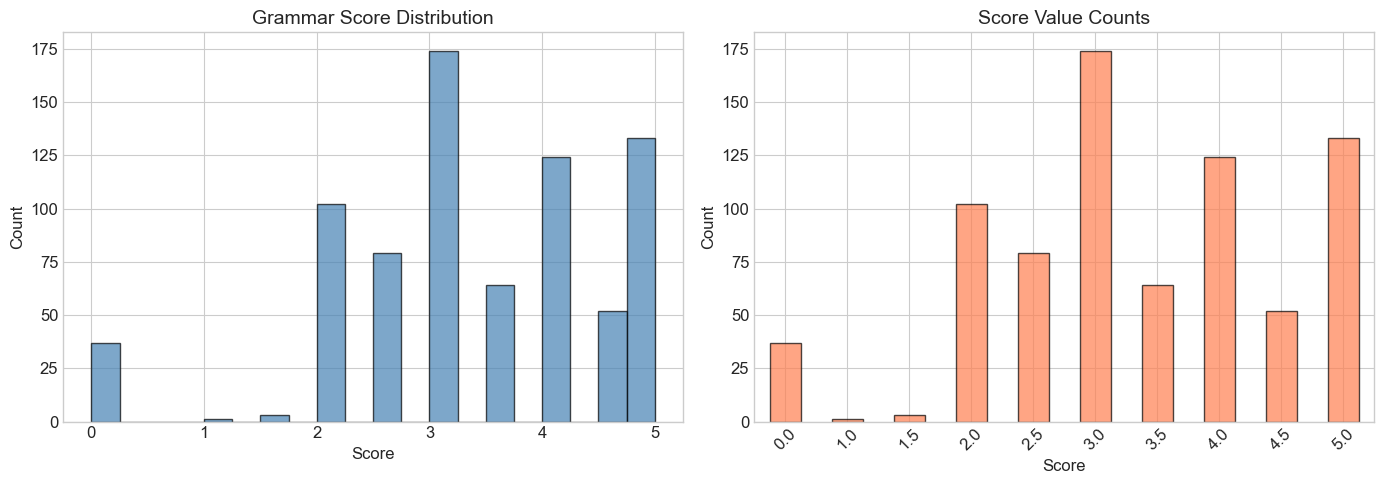


Score statistics:
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [49]:
# Score distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df['label'].hist(bins=20, ax=axes[0], color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Grammar Score Distribution', fontsize=14)
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Count')

# Value counts
score_counts = train_df['label'].value_counts().sort_index()
score_counts.plot(kind='bar', ax=axes[1], color='coral', edgecolor='black', alpha=0.7)
axes[1].set_title('Score Value Counts', fontsize=14)
axes[1].set_xlabel('Score')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nScore statistics:')
print(train_df['label'].describe())


## 3. Feature Extraction

We extract three types of features:
1. **Hand-crafted text features (52):** grammar errors, readability scores, vocabulary sophistication, clause structure
2. **Audio features (43):** MFCCs, pitch, energy, spectral centroid, speaking rate, pauses
3. **Whisper metadata (12):** avg_logprob, no_speech_prob, compression_ratio, temperature
4. **Sentence embeddings (50 PCA):** MiniLM-L6-v2 embeddings of transcript text


In [50]:
# Extract hand-crafted features (cached for speed)
if os.path.exists('train_features_v3.csv') and os.path.exists('test_features_v3.csv'):
    print('Loading cached features...')
    train_feat_df = pd.read_csv('train_features_v3.csv')
    test_feat_df = pd.read_csv('test_features_v3.csv')
else:
    print('Extracting features (this takes ~15 min with LanguageTool)...')
    train_feat_df = extract_all_features(
        train_df, train_transcripts, 'Dataset_Final/train', use_grammar_tool=True
    )
    test_feat_df = extract_all_features(
        test_df, test_transcripts, 'Dataset_Final/test', use_grammar_tool=True
    )
    train_feat_df.to_csv('train_features_v3.csv', index=False)
    test_feat_df.to_csv('test_features_v3.csv', index=False)
    print('Features saved to CSV.')

print(f'Hand-crafted + Whisper features: {train_feat_df.shape[1] - 1}')
print(f'Train shape: {train_feat_df.shape}')
print(f'Test shape: {test_feat_df.shape}')


Extracting features (this takes ~15 min with LanguageTool)...
Initializing LanguageTool (this may take a moment)...
Done.
  [50/769] features extracted
  [100/769] features extracted
  [150/769] features extracted
  [200/769] features extracted
  [250/769] features extracted
  [300/769] features extracted
  [350/769] features extracted
  [400/769] features extracted
  [450/769] features extracted
  [500/769] features extracted
  [550/769] features extracted
  [600/769] features extracted
  [650/769] features extracted
  [700/769] features extracted
  [750/769] features extracted
  [769/769] features extracted
Initializing LanguageTool (this may take a moment)...
Done.
  [50/216] features extracted
  [100/216] features extracted
  [150/216] features extracted
  [200/216] features extracted
  [216/216] features extracted
Features saved to CSV.
Hand-crafted + Whisper features: 75
Train shape: (769, 76)
Test shape: (216, 76)


In [51]:
# Generate sentence embeddings
print('Loading sentence-transformer: all-MiniLM-L6-v2')
st_model = SentenceTransformer('all-MiniLM-L6-v2')

train_texts = [train_transcripts.get(f, {}).get('text', '').strip() or 'empty' 
               for f in train_df['filename']]
test_texts = [test_transcripts.get(f, {}).get('text', '').strip() or 'empty' 
              for f in test_df['filename']]

print('Encoding transcripts...')
train_embeddings = st_model.encode(train_texts, show_progress_bar=True, batch_size=32)
test_embeddings = st_model.encode(test_texts, show_progress_bar=True, batch_size=32)

print(f'Embedding shape: {train_embeddings.shape}')

# PCA reduce to 50 dims
pca = PCA(n_components=50, random_state=42)
train_emb_pca = pca.fit_transform(train_embeddings)
test_emb_pca = pca.transform(test_embeddings)
print(f'PCA 50-dim captures {pca.explained_variance_ratio_.sum():.1%} of variance')


Loading sentence-transformer: all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoding transcripts...


Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Embedding shape: (769, 384)
PCA 50-dim captures 74.9% of variance


In [52]:
# Combine all features
train_fnames = train_df['filename'].tolist()
test_fnames = test_df['filename'].tolist()

# Align hand-crafted features
train_feat_df = train_feat_df.set_index('filename').loc[train_fnames].reset_index()
test_feat_df = test_feat_df.set_index('filename').loc[test_fnames].reset_index()

hc_cols = [c for c in train_feat_df.columns if c != 'filename']
X_hc_train = train_feat_df[hc_cols].values.astype(np.float32)
X_hc_test = test_feat_df[hc_cols].values.astype(np.float32)

# Stack: hand-crafted + PCA embeddings
X_train = np.hstack([X_hc_train, train_emb_pca]).astype(np.float32)
X_test = np.hstack([X_hc_test, test_emb_pca]).astype(np.float32)

# Handle NaN/Inf
X_train = np.nan_to_num(X_train, nan=0, posinf=0, neginf=0)
X_test = np.nan_to_num(X_test, nan=0, posinf=0, neginf=0)

y_train = train_df.set_index('filename').loc[train_fnames, 'label'].values

feature_names = hc_cols + [f'pca_emb_{i}' for i in range(50)]
print(f'Total features: {X_train.shape[1]} ({len(hc_cols)} HC + 50 PCA embeddings)')


Total features: 125 (75 HC + 50 PCA embeddings)


## 4. Feature Analysis


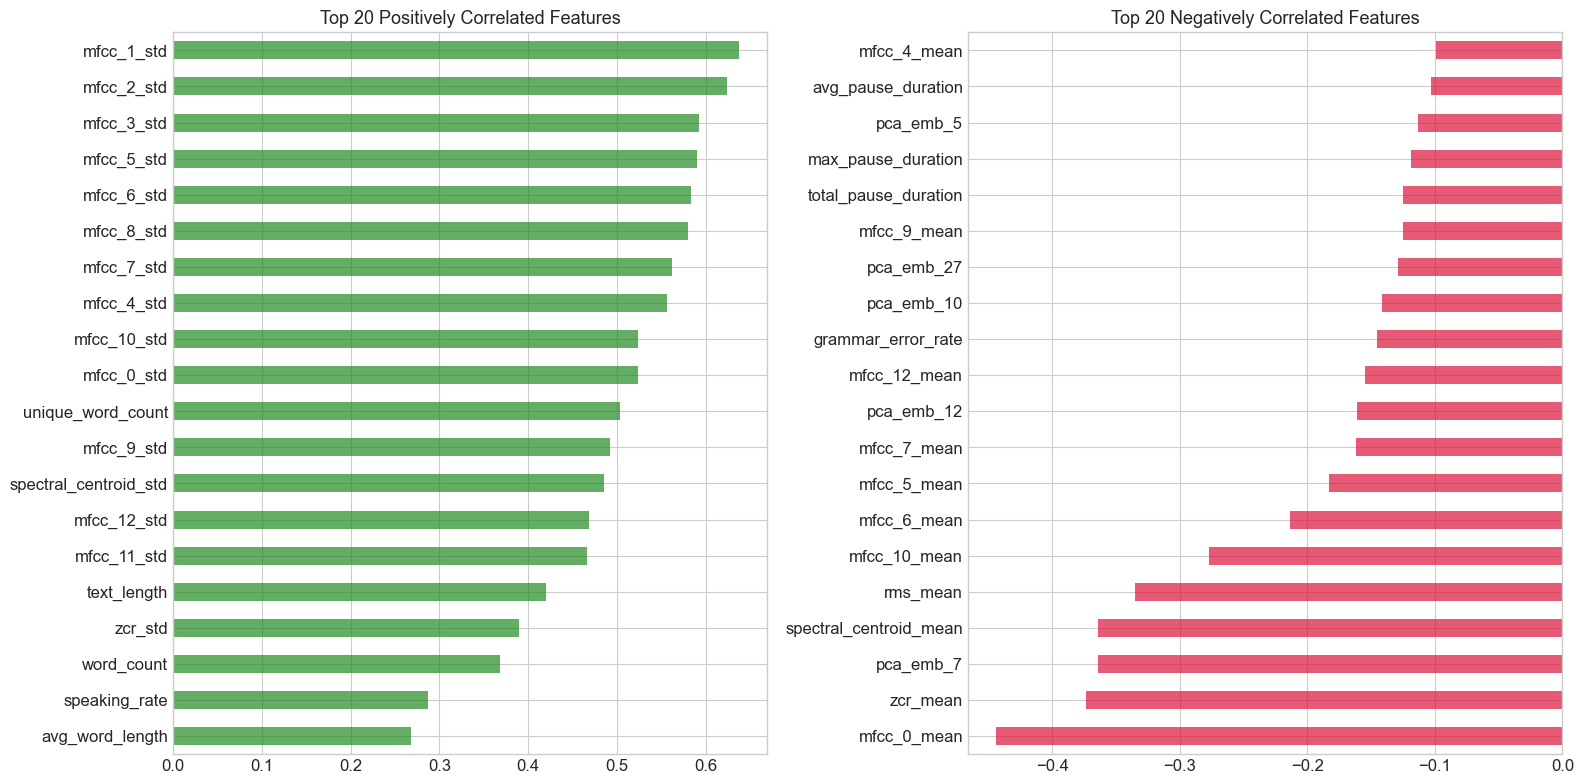

In [53]:
# Correlation with target
corr_df = pd.DataFrame(X_train, columns=feature_names)
corr_df['label'] = y_train
correlations = corr_df.corr()['label'].drop('label').sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top positive
top_pos = correlations.head(20)
top_pos.plot(kind='barh', ax=axes[0], color='forestgreen', alpha=0.7)
axes[0].set_title('Top 20 Positively Correlated Features', fontsize=13)
axes[0].invert_yaxis()

# Top negative
top_neg = correlations.tail(20)
top_neg.plot(kind='barh', ax=axes[1], color='crimson', alpha=0.7)
axes[1].set_title('Top 20 Negatively Correlated Features', fontsize=13)
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()


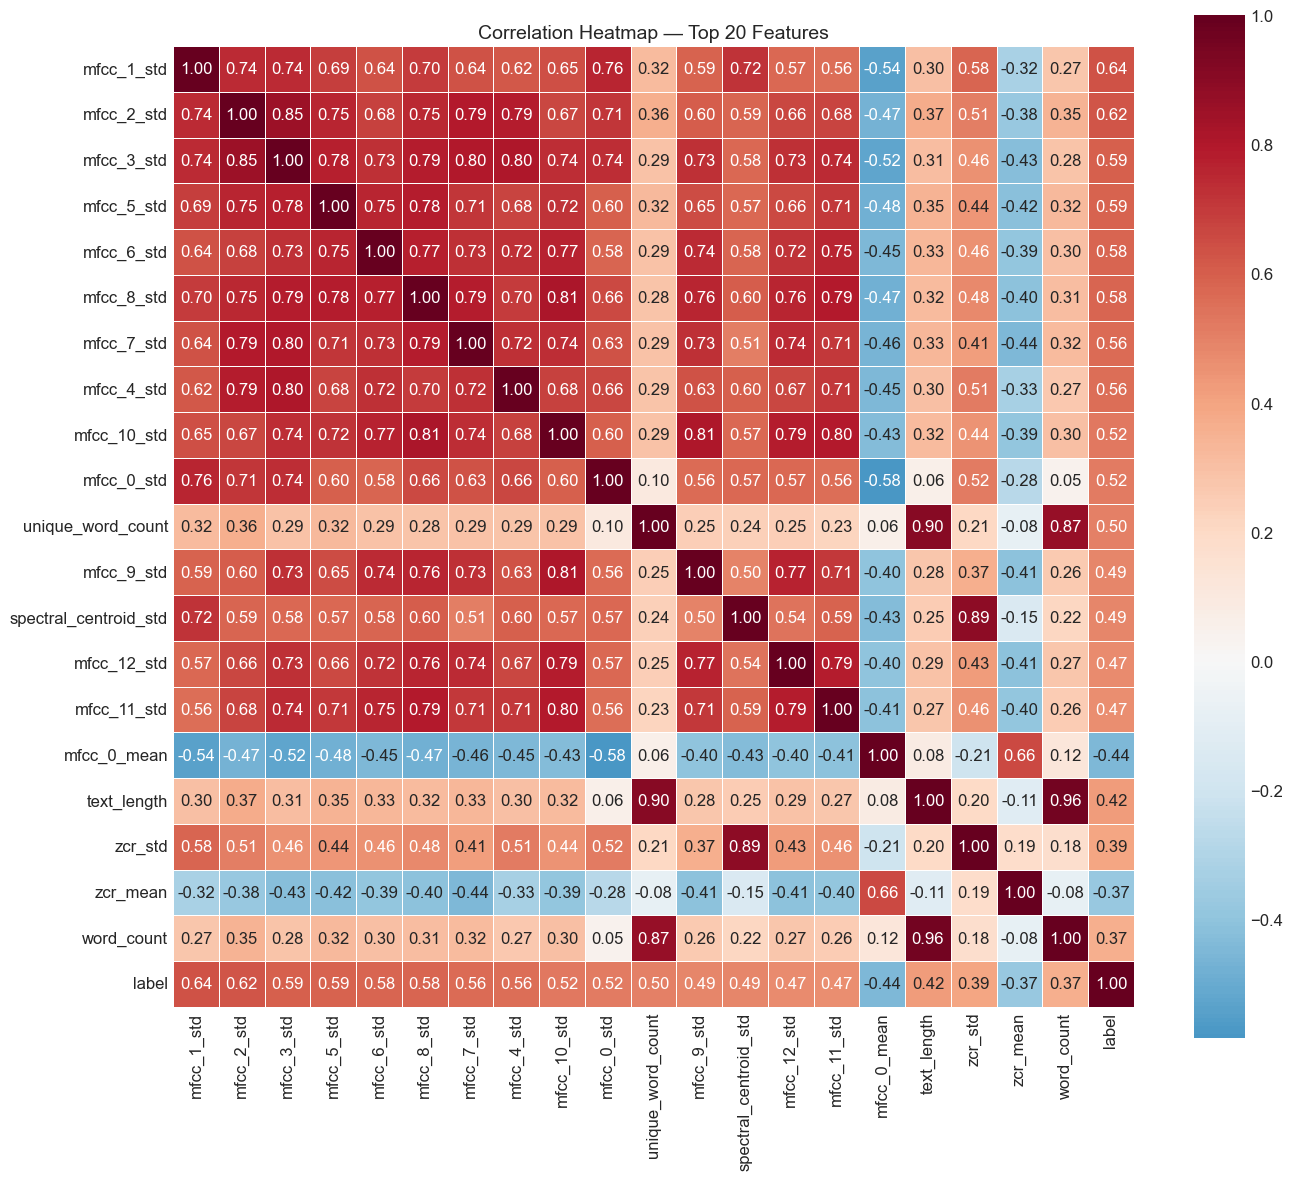

In [54]:
# Correlation heatmap of top features
top_features = list(correlations.abs().sort_values(ascending=False).head(20).index)
top_features.append('label')

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_df[top_features].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title('Correlation Heatmap — Top 20 Features', fontsize=14)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Model Training & Evaluation

**Approach:** XGBoost with strong regularization on all features (HC + PCA embeddings).
We also train Ridge as a baseline for comparison.


In [55]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# === XGBoost ===
xgb = XGBRegressor(
    n_estimators=500, max_depth=4, learning_rate=0.03,
    subsample=0.7, colsample_bytree=0.5,
    reg_alpha=1.0, reg_lambda=5.0,
    min_child_weight=5, gamma=0.1,
    random_state=42, verbosity=0
)

xgb_oof = cross_val_predict(xgb, X_train, y_train, cv=kf)
xgb_oof = np.clip(xgb_oof, 0, 5)
xgb_rmse = np.sqrt(mean_squared_error(y_train, xgb_oof))
xgb_pearson, _ = stats.pearsonr(y_train, xgb_oof)
print(f'XGBoost:  RMSE = {xgb_rmse:.4f}, Pearson R = {xgb_pearson:.4f}')

# === Ridge (baseline) ===
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ridge = Ridge(alpha=100)
ridge_oof = cross_val_predict(ridge, X_train_scaled, y_train, cv=kf)
ridge_oof = np.clip(ridge_oof, 0, 5)
ridge_rmse = np.sqrt(mean_squared_error(y_train, ridge_oof))
ridge_pearson, _ = stats.pearsonr(y_train, ridge_oof)
print(f'Ridge:    RMSE = {ridge_rmse:.4f}, Pearson R = {ridge_pearson:.4f}')


XGBoost:  RMSE = 0.7014, Pearson R = 0.8247
Ridge:    RMSE = 0.7303, Pearson R = 0.8077


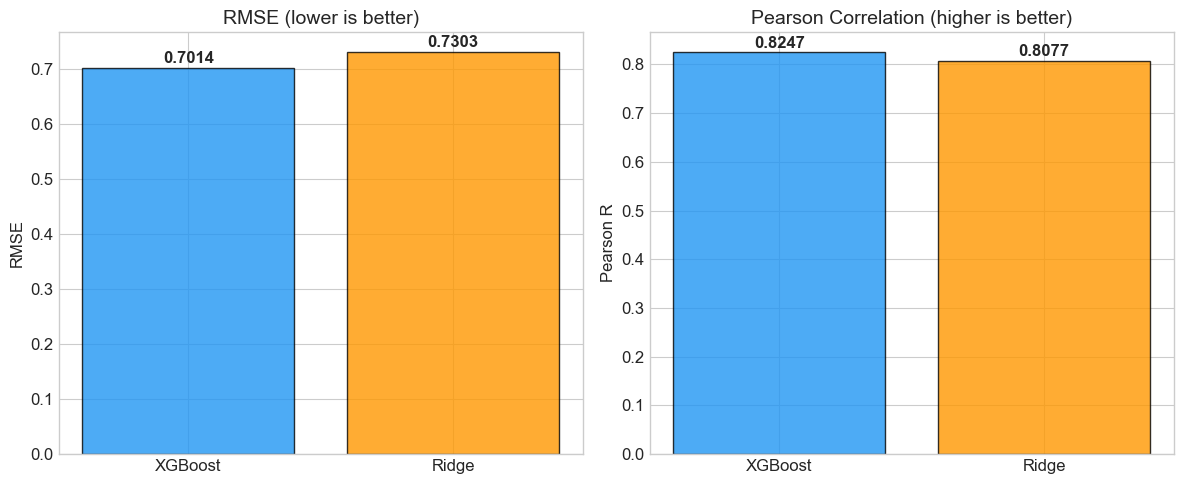

In [56]:
# Model comparison visualization
models = ['XGBoost', 'Ridge']
rmses = [xgb_rmse, ridge_rmse]
pearsons = [xgb_pearson, ridge_pearson]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bars1 = axes[0].bar(models, rmses, color=['#2196F3', '#FF9800'], alpha=0.8, edgecolor='black')
axes[0].set_title('RMSE (lower is better)', fontsize=14)
axes[0].set_ylabel('RMSE')
for bar, val in zip(bars1, rmses):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.4f}', 
                ha='center', fontsize=12, fontweight='bold')

bars2 = axes[1].bar(models, pearsons, color=['#2196F3', '#FF9800'], alpha=0.8, edgecolor='black')
axes[1].set_title('Pearson Correlation (higher is better)', fontsize=14)
axes[1].set_ylabel('Pearson R')
for bar, val in zip(bars2, pearsons):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.4f}', 
                ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Results Analysis


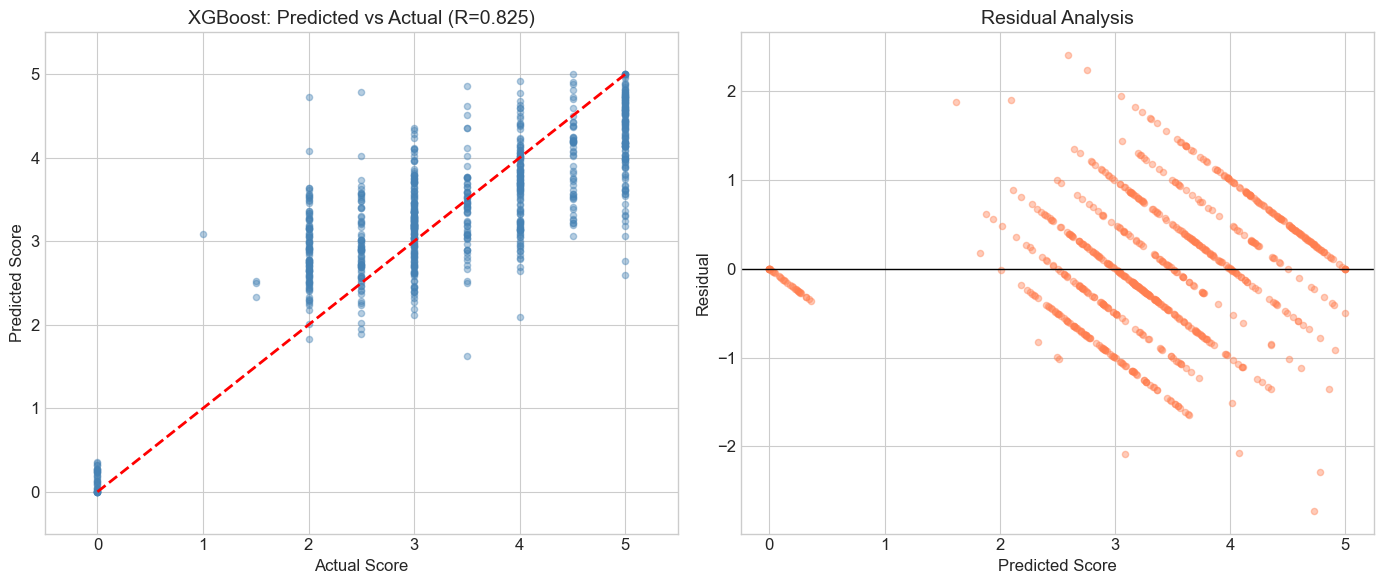

Residual stats: mean=-0.0006, std=0.7014


In [57]:
# Predicted vs Actual
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_train, xgb_oof, alpha=0.4, s=20, color='steelblue')
axes[0].plot([0, 5], [0, 5], 'r--', lw=2)
axes[0].set_xlabel('Actual Score', fontsize=12)
axes[0].set_ylabel('Predicted Score', fontsize=12)
axes[0].set_title(f'XGBoost: Predicted vs Actual (R={xgb_pearson:.3f})', fontsize=14)
axes[0].set_xlim(-0.5, 5.5)
axes[0].set_ylim(-0.5, 5.5)

# Residual analysis
residuals = y_train - xgb_oof
axes[1].scatter(xgb_oof, residuals, alpha=0.4, s=20, color='coral')
axes[1].axhline(y=0, color='black', linestyle='-', lw=1)
axes[1].set_xlabel('Predicted Score', fontsize=12)
axes[1].set_ylabel('Residual', fontsize=12)
axes[1].set_title('Residual Analysis', fontsize=14)

plt.tight_layout()
plt.savefig('predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Residual stats: mean={residuals.mean():.4f}, std={residuals.std():.4f}')


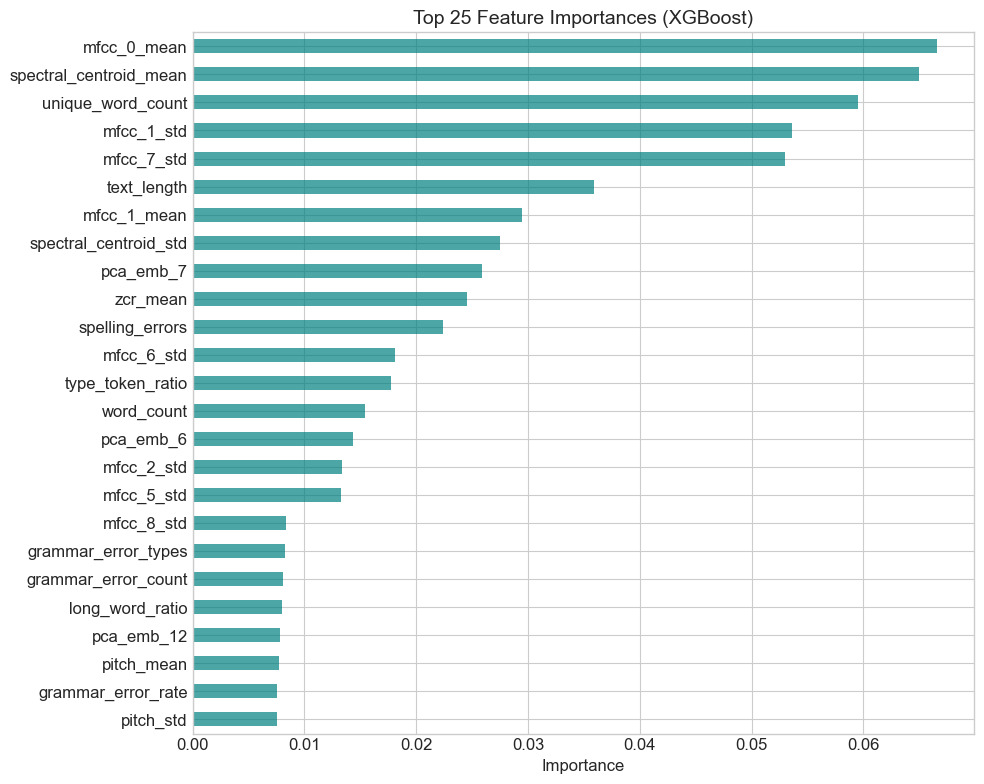

In [58]:
# Feature importance
xgb.fit(X_train, y_train)

importance = pd.Series(xgb.feature_importances_, index=feature_names)
top_imp = importance.sort_values(ascending=False).head(25)

fig, ax = plt.subplots(figsize=(10, 8))
top_imp.sort_values().plot(kind='barh', ax=ax, color='teal', alpha=0.7)
ax.set_title('Top 25 Feature Importances (XGBoost)', fontsize=14)
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Generate Submission


In [59]:
# Train final model on all training data
xgb.fit(X_train, y_train)
test_preds = xgb.predict(X_test)
test_preds = np.clip(test_preds, 0, 5)

# Create submission
submission = test_df[['filename']].copy()
submission['label'] = test_preds
submission.to_csv('submission.csv', index=False)

print(f'Submission saved: submission.csv')
print(f'Predictions: mean={test_preds.mean():.3f}, std={test_preds.std():.3f}, '
      f'min={test_preds.min():.3f}, max={test_preds.max():.3f}')
print(f'\nFirst 5 predictions:')
print(submission.head())


Submission saved: submission.csv
Predictions: mean=3.166, std=0.646, min=1.754, max=5.000

First 5 predictions:
        filename     label
0  audio_128.wav  3.011875
1  audio_156.wav  3.616827
2   audio_19.wav  4.169541
3  audio_108.wav  2.594349
4  audio_206.wav  2.870445


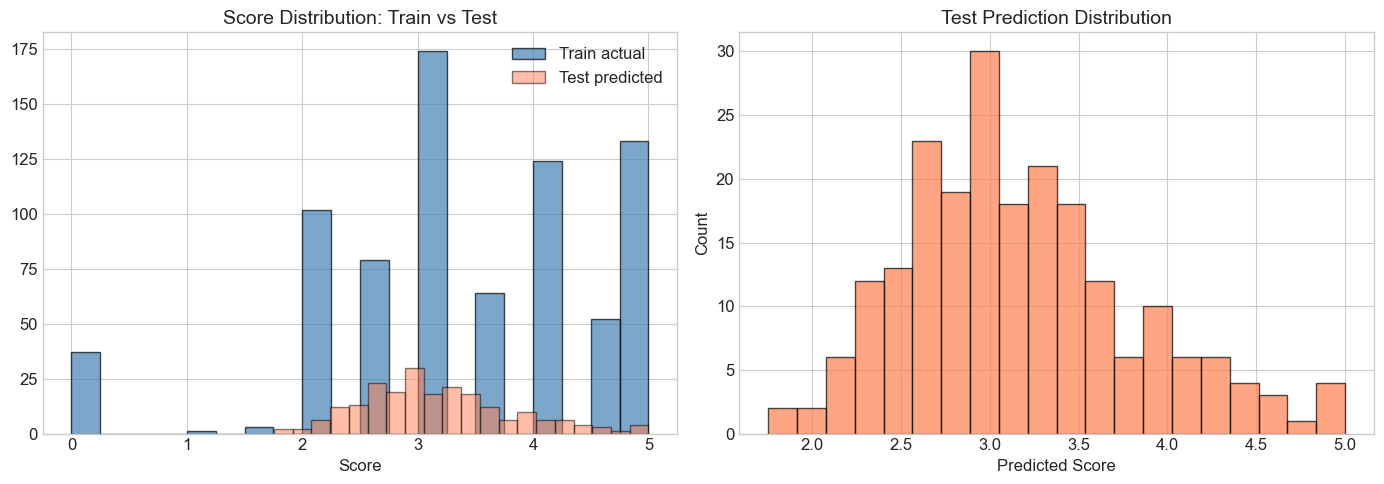

In [60]:
# Test prediction distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(y_train, bins=20, alpha=0.7, color='steelblue', edgecolor='black', label='Train actual')
axes[0].hist(test_preds, bins=20, alpha=0.5, color='coral', edgecolor='black', label='Test predicted')
axes[0].set_title('Score Distribution: Train vs Test', fontsize=14)
axes[0].set_xlabel('Score')
axes[0].legend()

axes[1].hist(test_preds, bins=20, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_title('Test Prediction Distribution', fontsize=14)
axes[1].set_xlabel('Predicted Score')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('test_predictions.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Summary

### Pipeline
```
Audio (.wav) → Whisper small → Transcript + Metadata → Feature Engineering → XGBoost → Score (0-5)
```

### Features (v3)
- **52 text features:** word counts, grammar errors (LanguageTool), readability (Flesch-Kincaid, ARI), vocabulary sophistication, clause structure, discourse markers
- **43 audio features:** MFCCs (13 × mean + std), pitch, energy, spectral centroid, speaking rate, pauses
- **12 Whisper metadata:** avg_logprob, no_speech_prob, compression_ratio, temperature (mean/max/std)
- **50 PCA embeddings:** MiniLM-L6-v2 sentence embeddings reduced from 384-dim

### Key Findings
- PCA embeddings fed directly to XGBoost outperform blending strategies
- Whisper metadata (confidence scores) provides signal about speech clarity
- Single strong model > complex ensemble for this dataset size (769 samples)
